In [ ]:
!pip install -q wordcloud xgboost scikit-learn pandas numpy matplotlib seaborn


# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

pd.set_option("display.max_colwidth", 100)
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Dataset downloaded and loaded successfully!")
print("Shape of dataset:", df.shape)
df.head(10)


# %%
# Basic dataset facts
print("Number of rows (records):", df.shape[0])
print("Number of columns (features):", df.shape[1])
print("\nColumn names:", list(df.columns))


Dataset downloaded and loaded successfully!
Shape of dataset: (5572, 2)
Number of rows (records): 5572
Number of columns (features): 2

Column names: ['label', 'message']


In [ ]:
print("Number of records:", df.shape[0])
print("Number of features (excluding target):", df.shape[1] - 1)


# %%
# Data types
df.info()


# %%
# Missing values
print("Missing values per column:")
print(df.isnull().sum())


# %%
# Duplicate records
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")
df[df.duplicated()].head()


# %%
# Unique values
print("Unique values in 'label':", df['label'].unique())
print("\nValue counts:\n", df['label'].value_counts())
print("\nNumber of unique messages:", df['message'].nunique())


# %%
# Statistical summary of message length (numeric proxy feature for text)
df['message_length'] = df['message'].apply(len)
df['word_count'] = df['message'].apply(lambda x: len(x.split()))

df[['message_length', 'word_count']].describe()


# %%
# Class distribution (%)
class_dist = df['label'].value_counts(normalize=True) * 100
print("Class distribution (%):")
print(class_dist)


Number of records: 5572
Number of features (excluding target): 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
Missing values per column:
label      0
message    0
dtype: int64
Number of duplicate rows: 403
Unique values in 'label': ['ham' 'spam']

Value counts:
 label
ham     4825
spam     747
Name: count, dtype: int64

Number of unique messages: 5169
Class distribution (%):
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [ ]:
print("Missing values:\n", df.isnull().sum())


# %%
# 4.2 Remove duplicate records
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
after = df.shape[0]
print(f"Removed {before - after} duplicate rows.")
print("New shape:", df.shape)


# %%
# 4.3 Check for incorrect / inconsistent label values
print("Unique labels after cleaning:", df['label'].unique())
# Should only contain 'ham' and 'spam' — if not, those rows would need to be dropped/fixed


# %%
# 4.4 Outlier check on message_length using IQR method
Q1 = df['message_length'].quantile(0.25)
Q3 = df['message_length'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['message_length'] < lower_bound) | (df['message_length'] > upper_bound)]
print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
print(f"Number of outlier messages (by length): {outliers.shape[0]}")

# NOTE: We do NOT drop these outliers — in spam detection, unusually long/short
# messages are often genuinely informative (e.g., spam messages tend to be longer
# with promotional text). Removing them could remove valuable signal.


# %%
# 4.5 Categorical variable: encode target label
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})
df[['label', 'label_num']].drop_duplicates()


# %%
# 4.6 Basic text cleaning function (for later feature engineering / EDA on word content)
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)          # remove URLs
    text = re.sub(r'\d+', '', text)                       # remove numbers
    text = text.translate(str.maketrans('', '', string.punctuation))  # remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()               # remove extra whitespace
    return text

df['clean_message'] = df['message'].apply(clean_text)
df[['message', 'clean_message']].head()


# %%
# Final check after preprocessing
print("Final dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows remaining:", df.duplicated().sum())
df.head()

Missing values:
 label             0
message           0
message_length    0
word_count        0
dtype: int64
Removed 403 duplicate rows.
New shape: (5169, 4)
Unique labels after cleaning: ['ham' 'spam']
Lower bound: -88.50, Upper bound: 243.50
Number of outlier messages (by length): 64
Final dataset shape: (5169, 6)

Missing values:
 label             0
message           0
message_length    0
word_count        0
label_num         0
clean_message     0
dtype: int64

Duplicate rows remaining: 0


,label,message,message_length,word_count,label_num,clean_message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...",111,20,0,go until jurong point crazy available only in bugis n great world la e buffet cine there got amo...
1,ham,Ok lar... Joking wif u oni...,29,6,0,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,155,28,1,free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionst...
3,ham,U dun say so early hor... U c already then say...,49,11,0,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives around here though",61,13,0,nah i dont think he goes to usf he lives around here though


In [ ]:
# 5.1 Count plot — Class distribution (Spam vs Ham)
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='label', palette=['#4CAF50', '#E53935'])
plt.title("Distribution of Spam vs Ham Messages")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


# %%
# 5.2 Bar chart — Percentage share of each class
plt.figure(figsize=(6,4))
class_pct = df['label'].value_counts(normalize=True) * 100
class_pct.plot(kind='bar', color=['#4CAF50', '#E53935'])
plt.title("Percentage Share: Spam vs Ham")
plt.xlabel("Label")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()


# %%
# 5.3 Histogram — Distribution of message length by class
plt.figure(figsize=(9,5))
sns.histplot(data=df, x='message_length', hue='label', bins=50, kde=True, palette=['#4CAF50', '#E53935'])
plt.title("Distribution of Message Length by Class")
plt.xlabel("Message Length (characters)")
plt.ylabel("Frequency")
plt.show()


# %%
# 5.4 Histogram — Distribution of word count by class
plt.figure(figsize=(9,5))
sns.histplot(data=df, x='word_count', hue='label', bins=40, kde=True, palette=['#4CAF50', '#E53935'])
plt.title("Distribution of Word Count by Class")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()


# %%
# 5.5 Box plot — Message length by class (spot outliers visually)
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='label', y='message_length', palette=['#4CAF50', '#E53935'])
plt.title("Box Plot: Message Length by Class")
plt.xlabel("Label")
plt.ylabel("Message Length (characters)")
plt.show()


# %%
# 5.6 Box plot — Word count by class
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='label', y='word_count', palette=['#4CAF50', '#E53935'])
plt.title("Box Plot: Word Count by Class")
plt.xlabel("Label")
plt.ylabel("Word Count")
plt.show()


# %%
# 5.7 Scatter plot — Message length vs Word count, colored by class
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='word_count', y='message_length', hue='label', alpha=0.5, palette=['#4CAF50', '#E53935'])
plt.title("Scatter Plot: Word Count vs Message Length")
plt.xlabel("Word Count")
plt.ylabel("Message Length (characters)")
plt.show()


# %%
# 5.8 Correlation heatmap — numeric features
numeric_df = df[['message_length', 'word_count', 'label_num']]

plt.figure(figsize=(6,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


# %%
# 5.9 Word Clouds — most frequent words in Spam vs Ham messages
from wordcloud import WordCloud

spam_text = " ".join(df[df['label'] == 'spam']['clean_message'])
ham_text = " ".join(df[df['label'] == 'ham']['clean_message'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_spam = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate(spam_text)
axes[0].imshow(wc_spam, interpolation='bilinear')
axes[0].set_title("Most Common Words in SPAM Messages", fontsize=14)
axes[0].axis('off')

wc_ham = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate(ham_text)
axes[1].imshow(wc_ham, interpolation='bilinear')
axes[1].set_title("Most Common Words in HAM Messages", fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()


# %%
# 5.10 Top 20 most frequent words — Spam vs Ham (bar charts)
from collections import Counter

def get_top_words(text_series, n=20):
    words = " ".join(text_series).split()
    return Counter(words).most_common(n)

top_spam_words = get_top_words(df[df['label']=='spam']['clean_message'])
top_ham_words  = get_top_words(df[df['label']=='ham']['clean_message'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=[c for _, c in top_spam_words], y=[w for w, _ in top_spam_words], ax=axes[0], color='#E53935')
axes[0].set_title("Top 20 Words in Spam Messages")
axes[0].set_xlabel("Frequency")

sns.barplot(x=[c for _, c in top_ham_words], y=[w for w, _ in top_ham_words], ax=axes[1], color='#4CAF50')
axes[1].set_title("Top 20 Words in Ham Messages")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
# ============================================
# STEP 1: PREPARE DATA FOR MACHINE LEARNING
# ============================================

import pandas as pd
import numpy as np

# Check the required columns
print("Available columns:", df.columns.tolist())

# Remove rows with missing text or labels
df = df.dropna(subset=['clean_message', 'label_num']).copy()

# Convert text to string
df['clean_message'] = df['clean_message'].astype(str)

# Convert labels to integers
df['label_num'] = df['label_num'].astype(int)

# Define input and target
X = df['clean_message']
y = df['label_num']

print("\nDataset prepared successfully!")
print("Total messages:", len(df))
print("\nTarget distribution:")
print(y.value_counts())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Available columns: ['label', 'message', 'message_length', 'word_count', 'label_num', 'clean_message']

Dataset prepared successfully!
Total messages: 5169

Target distribution:
label_num
0    4516
1     653
Name: count, dtype: int64

Input shape: (5169,)
Target shape: (5169,)


In [ ]:
# ============================================
# STEP 2: TRAIN-TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining data distribution:")
print(y_train.value_counts())

print("\nTesting data distribution:")
print(y_test.value_counts())

Data split completed successfully!

Training samples: 4135
Testing samples: 1034

Training data distribution:
label_num
0    3613
1     522
Name: count, dtype: int64

Testing data distribution:
label_num
0    903
1    131
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 3: TF-IDF FEATURE EXTRACTION
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english',
    sublinear_tf=True
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("\nTraining feature matrix shape:", X_train_tfidf.shape)
print("Testing feature matrix shape:", X_test_tfidf.shape)

print("\nNumber of vocabulary features:", len(tfidf.vocabulary_))

# Display some vocabulary terms
print("\nSample vocabulary:")
print(list(tfidf.vocabulary_.keys())[:20])

TF-IDF conversion completed!

Training feature matrix shape: (4135, 5000)
Testing feature matrix shape: (1034, 5000)

Number of vocabulary features: 5000

Sample vocabulary:
['home', 'babe', 'home babe', 'yup', 'having', 'lunch', 'buffet', 'eat', 'having lunch', 'ok', 'need', 'change', 'said', 'ok need', 'need change', 'best', 'ur', 'exam', 'later', 'best ur']


In [ ]:
# ============================================
# STEP 4: DECISION TREE CLASSIFIER
# ============================================

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
decision_tree = DecisionTreeClassifier(
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42
)

# Train the model
decision_tree.fit(X_train_tfidf, y_train)

# Make predictions
dt_predictions = decision_tree.predict(X_test_tfidf)

print("Decision Tree model trained successfully!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(dt_predictions[:10].tolist())

Decision Tree model trained successfully!

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
# ============================================
# STEP 5: XGBOOST CLASSIFIER
# ============================================

from xgboost import XGBClassifier

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_tfidf, y_train)

# Make predictions
xgb_predictions = xgb_model.predict(X_test_tfidf)

print("XGBoost model trained successfully!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(xgb_predictions[:10].tolist())

XGBoost model trained successfully!

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
# ============================================
# STEP 6: MODEL EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Store model predictions
predictions = {
    "Decision Tree": dt_predictions,
    "XGBoost": xgb_predictions
}

# Store evaluation results
results = []

for model_name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            zero_division=0
        )
    )

# Create the comparison DataFrame
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)


Decision Tree
Accuracy : 0.9497
Precision: 0.8015
Recall   : 0.8015
F1-Score : 0.8015

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      0.97      0.97       903
        Spam       0.80      0.80      0.80       131

    accuracy                           0.95      1034
   macro avg       0.89      0.89      0.89      1034
weighted avg       0.95      0.95      0.95      1034


XGBoost
Accuracy : 0.9623
Precision: 0.9792
Recall   : 0.7176
F1-Score : 0.8282

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.98      0.72      0.83       131

    accuracy                           0.96      1034
   macro avg       0.97      0.86      0.90      1034
weighted avg       0.96      0.96      0.96      1034


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,94.97%,80.15%,80.15%,80.15%
1,XGBoost,96.23%,97.92%,71.76%,82.82%


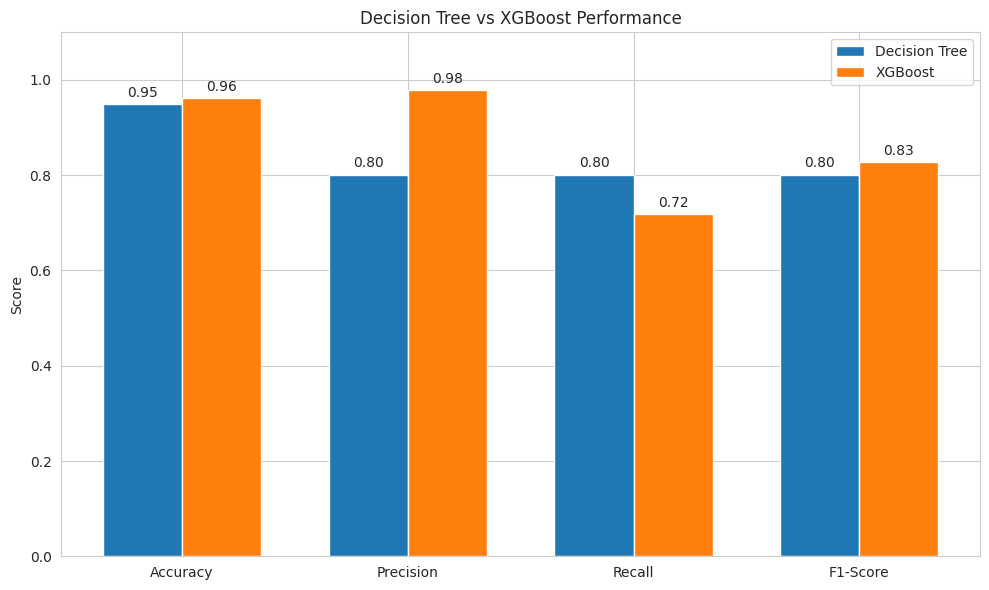

In [ ]:
# ============================================
# STEP 7: MODEL COMPARISON GRAPH
# ============================================

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

dt_values = results_df.loc[
    results_df["Model"] == "Decision Tree", metrics
].iloc[0].values

xgb_values = results_df.loc[
    results_df["Model"] == "XGBoost", metrics
].iloc[0].values

bars1 = ax.bar(
    x - width / 2,
    dt_values,
    width,
    label="Decision Tree"
)

bars2 = ax.bar(
    x + width / 2,
    xgb_values,
    width,
    label="XGBoost"
)

ax.set_title("Decision Tree vs XGBoost Performance")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)

ax.legend()
ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


Confusion Matrix: Decision Tree
[[877  26]
 [ 26 105]]


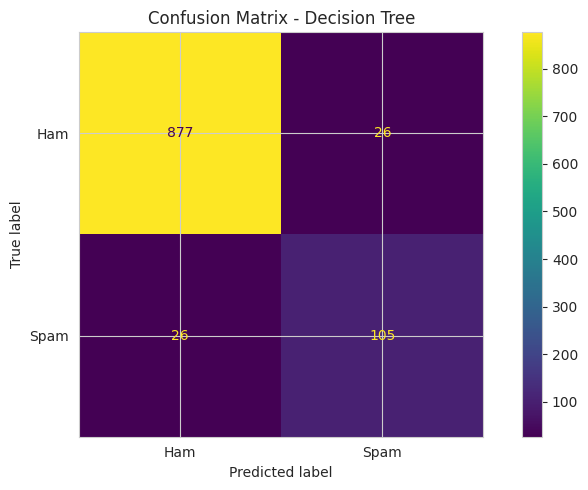


Confusion Matrix: XGBoost
[[901   2]
 [ 37  94]]


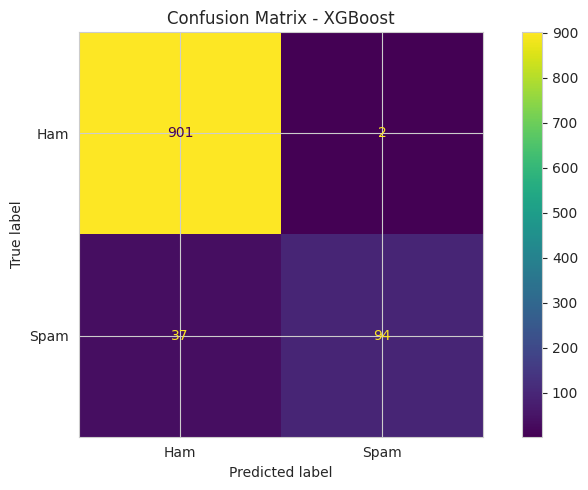

In [ ]:
# ============================================
# STEP 8: CONFUSION MATRICES
# ============================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    print(f"\nConfusion Matrix: {model_name}")
    print(cm)

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ham", "Spam"]
    )

    display_obj.plot()

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================
# STEP 9: 5-FOLD CROSS-VALIDATION
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Define models with TF-IDF pipelines
cv_models = {
    "Decision Tree": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )),
        ("classifier", DecisionTreeClassifier(
            max_depth=30,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

cv_results = []

for model_name, pipeline in cv_models.items():

    print(f"\nRunning cross-validation for {model_name}...")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": model_name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1-Score": scores["test_f1"].mean(),
        "F1 Std Dev": scores["test_f1"].std()
    })

    print("Mean Accuracy:", round(scores["test_accuracy"].mean(), 4))
    print("Mean Precision:", round(scores["test_precision"].mean(), 4))
    print("Mean Recall:", round(scores["test_recall"].mean(), 4))
    print("Mean F1-Score:", round(scores["test_f1"].mean(), 4))
    print("F1 Standard Deviation:", round(scores["test_f1"].std(), 4))

cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARISON")

display(
    cv_results_df.style.format({
        "Mean Accuracy": "{:.2%}",
        "Mean Precision": "{:.2%}",
        "Mean Recall": "{:.2%}",
        "Mean F1-Score": "{:.2%}",
        "F1 Std Dev": "{:.4f}"
    })
)

In [ ]:
# ============================================
# STEP 10: TEST WITH CUSTOM MESSAGES
# ============================================

def predict_spam(message):

    # Convert message into TF-IDF features
    message_tfidf = tfidf.transform([message])

    # Make predictions
    dt_prediction = decision_tree.predict(message_tfidf)[0]
    xgb_prediction = xgb_model.predict(message_tfidf)[0]

    # Convert numerical predictions into labels
    labels = {
        0: "HAM - Normal Message",
        1: "SPAM - Unwanted Message"
    }

    print("\nMessage:", message)

    print("\nDecision Tree Prediction:")
    print(labels[int(dt_prediction)])

    print("\nXGBoost Prediction:")
    print(labels[int(xgb_prediction)])


# Try some example messages
predict_spam("Hey, are we meeting tomorrow?")
predict_spam("Congratulations! You have won a free prize. Claim now!")


Message: Hey, are we meeting tomorrow?

Decision Tree Prediction:
HAM - Normal Message

XGBoost Prediction:
HAM - Normal Message

Message: Congratulations! You have won a free prize. Claim now!

Decision Tree Prediction:
SPAM - Unwanted Message

XGBoost Prediction:
SPAM - Unwanted Message


In [ ]:
# ============================================
# STEP 11: SAVE TRAINED MODELS
# ============================================

import joblib
import os

# Create a folder for saved models
os.makedirs("saved_models", exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "saved_models/tfidf_vectorizer.pkl"
)

# Save Decision Tree
joblib.dump(
    decision_tree,
    "saved_models/decision_tree_model.pkl"
)

# Save XGBoost
joblib.dump(
    xgb_model,
    "saved_models/xgboost_model.pkl"
)

print("All models saved successfully!")

print("\nSaved files:")
print("1. saved_models/tfidf_vectorizer.pkl")
print("2. saved_models/decision_tree_model.pkl")
print("3. saved_models/xgboost_model.pkl")

In [ ]:
# ============================================
# STEP 12: SELECT BEST MODEL
# ============================================

best_model_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

best_model_name = best_model_row["Model"]

print("BEST MODEL:", best_model_name)

print("\nPerformance:")
print(f"Accuracy : {best_model_row['Accuracy']:.4f}")
print(f"Precision: {best_model_row['Precision']:.4f}")
print(f"Recall   : {best_model_row['Recall']:.4f}")
print(f"F1-Score : {best_model_row['F1-Score']:.4f}")

BEST MODEL: XGBoost

Performance:
Accuracy : 0.9623
Precision: 0.9792
Recall   : 0.7176
F1-Score : 0.8282


In [6]:

# ============================================================
# STEP 13: FINAL PROJECT SUMMARY
# Spam Classification Using Decision Tree and XGBoost
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("       SPAM CLASSIFICATION PROJECT SUMMARY")
print("=" * 65)

# ------------------------------------------------------------
# 1. FIND THE DATASET
# ------------------------------------------------------------

if 'df' in globals() and isinstance(df, pd.DataFrame):
    dataset = df.copy()

elif 'data' in globals() and isinstance(data, pd.DataFrame):
    dataset = data.copy()

elif 'spam' in globals() and isinstance(spam, pd.DataFrame):
    dataset = spam.copy()

else:
    dataset = None

# ------------------------------------------------------------
# 2. DISPLAY DATASET INFORMATION
# ------------------------------------------------------------

print("\n1. DATASET INFORMATION")
print("-" * 65)

if dataset is not None:

    print("Total messages used:", len(dataset))
    print("Dataset shape:", dataset.shape)

    # Find the target label column
    if 'label_num' in dataset.columns:
        labels = pd.to_numeric(
            dataset['label_num'], errors='coerce'
        ).dropna()

    elif 'label' in dataset.columns:
        labels = dataset['label'].astype(str).str.lower().map({
            'ham': 0,
            'spam': 1
        }).dropna()

    else:
        labels = None

    if labels is not None:
        print("Ham messages:", int((labels == 0).sum()))
        print("Spam messages:", int((labels == 1).sum()))
    else:
        print("Label counts unavailable: target column not found.")

else:
    print("Dataset variable not found.")
    print("Run your dataset loading and preprocessing cells first.")

# ------------------------------------------------------------
# 3. DISPLAY MODEL INFORMATION
# ------------------------------------------------------------

print("\n2. MACHINE LEARNING MODELS")
print("-" * 65)

model_names = []

if 'decision_tree' in globals():
    model_names.append("Decision Tree Classifier")

if 'xgb_model' in globals():
    model_names.append("XGBoost Classifier")

if model_names:
    for i, name in enumerate(model_names, start=1):
        print(f"{i}. {name}")
else:
    print("Models not found. Run the model training cells first.")

# ------------------------------------------------------------
# 4. FEATURE EXTRACTION
# ------------------------------------------------------------

print("\n3. FEATURE EXTRACTION")
print("-" * 65)

if 'tfidf' in globals():
    print("Technique: TF-IDF Vectorization")
    print("Vocabulary size:", len(tfidf.vocabulary_))
else:
    print("TF-IDF vectorizer not found.")

# ------------------------------------------------------------
# 5. TEST SET MODEL PERFORMANCE
# ------------------------------------------------------------

print("\n4. TEST SET PERFORMANCE")
print("-" * 65)

if 'results_df' in globals() and isinstance(results_df, pd.DataFrame):

    print(results_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    ))

    if (
        not results_df.empty
        and 'F1-Score' in results_df.columns
        and 'Model' in results_df.columns
    ):
        valid_results = results_df.dropna(subset=['F1-Score'])

        if not valid_results.empty:
            best_row = valid_results.loc[
                valid_results['F1-Score'].idxmax()
            ]

            print("\nBest model by test-set F1-score:",
                  best_row['Model'])
            print("F1-score:", round(best_row['F1-Score'], 4))

else:
    print("Test results unavailable.")
    print("Run the model evaluation cell first.")

# ------------------------------------------------------------
# 6. CROSS-VALIDATION RESULTS
# ------------------------------------------------------------

print("\n5. FIVE-FOLD CROSS-VALIDATION")
print("-" * 65)

if (
    'cv_results_df' in globals()
    and isinstance(cv_results_df, pd.DataFrame)
):

    print(cv_results_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    ))

else:
    print("Cross-validation results unavailable.")
    print("Run the cross-validation cell first.")

# ------------------------------------------------------------
# 7. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n6. PROJECT CONCLUSION")
print("-" * 65)

print("""
This project demonstrates text-based spam classification
using machine learning.

The workflow includes:
1. Dataset collection and preprocessing.
2. Exploratory Data Analysis (EDA).
3. TF-IDF feature extraction.
4. Training a Decision Tree classifier.
5. Training an XGBoost classifier.
6. Evaluating models using accuracy, precision, recall,
   and F1-score.
7. Comparing models using five-fold cross-validation.
8. Testing predictions on new text messages.

The preferred model should be selected based on its measured
performance, particularly spam precision, spam recall,
and F1-score.

Note: The dataset used in this notebook contains SMS messages,
so the demonstrated application is SMS spam classification.
""")

print("=" * 65)
print("             PROJECT SUMMARY COMPLETED")
print("=" * 65)



       SPAM CLASSIFICATION PROJECT SUMMARY

1. DATASET INFORMATION
-----------------------------------------------------------------
Dataset variable not found.
Run your dataset loading and preprocessing cells first.

2. MACHINE LEARNING MODELS
-----------------------------------------------------------------
Models not found. Run the model training cells first.

3. FEATURE EXTRACTION
-----------------------------------------------------------------
TF-IDF vectorizer not found.

4. TEST SET PERFORMANCE
-----------------------------------------------------------------
Test results unavailable.
Run the model evaluation cell first.

5. FIVE-FOLD CROSS-VALIDATION
-----------------------------------------------------------------
Cross-validation results unavailable.
Run the cross-validation cell first.

6. PROJECT CONCLUSION
-----------------------------------------------------------------

This project demonstrates text-based spam classification
using machine learning.

The workflow includ